# Build and Analyze a Transportation Network

In [62]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

### Creating the Multi-Directional Graph for a 6 Cities Network

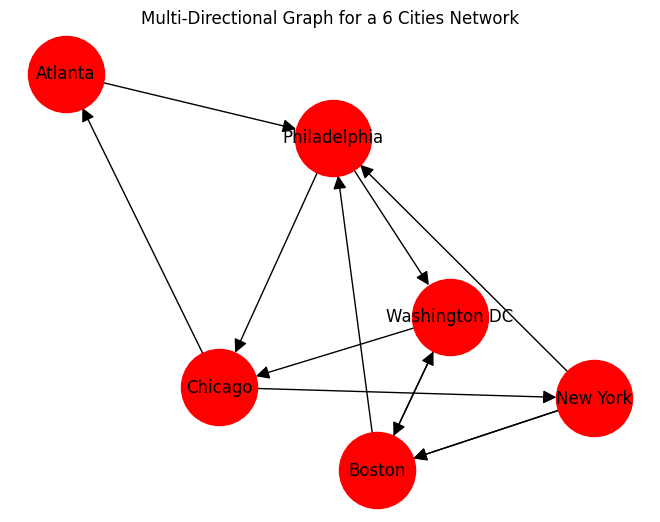

In [63]:
G = nx.MultiDiGraph()
import networkx as nx

G = nx.MultiDiGraph()

G.add_edges_from(
    [
        ("New York", "Boston", {"distance_miles": 215, "duration_hours": 3.5, "transport": "Train"}),
        ("New York", "Boston", {"distance_miles": 215, "duration_hours": 4.2, "transport": "Bus"}),
        ("New York", "Philadelphia", {"distance_miles": 95, "duration_hours": 1.5, "transport": "Train"}),
        ("Boston", "Philadelphia", {"distance_miles": 305, "duration_hours": 1.3, "transport": "Flight"}),
        ("Boston", "Washington DC", {"distance_miles": 440, "duration_hours": 1.5, "transport": "Flight"}),
        ("Philadelphia", "Washington DC", {"distance_miles": 140, "duration_hours": 2.0, "transport": "Train"}),
        ("Philadelphia", "Chicago", {"distance_miles": 760, "duration_hours": 2.3, "transport": "Flight"}),
        ("Washington DC", "Chicago", {"distance_miles": 700, "duration_hours": 2.0, "transport": "Flight"}),
        ("Chicago", "New York", {"distance_miles": 790, "duration_hours": 2.3, "transport": "Flight"}),
        ("Washington DC", "Boston", {"distance_miles": 440, "duration_hours": 7.5, "transport": "Car"}),
        ("Chicago", "Atlanta", {"distance_miles": 715, "duration_hours": 2.0, "transport": "Flight"}),
        ("Atlanta", "Philadelphia", {"distance_miles": 780, "duration_hours": 2.1, "transport": "Flight"}),
    ]
)

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color="red",
    font_color="black",
    node_size=3000,
    arrows=True,
    arrowsize=20
)

plt.title("Multi-Directional Graph for a 6 Cities Network")
plt.show()

In [64]:
print(f"Graph G has {G.number_of_nodes()} nodes\n{G.number_of_edges()} edges\nBetween 6 cities i.e {G.nodes} \nwhich are {G.edges(data=True)}\n\n")

for node in G.nodes():
    print("------------------------------------------")
    print(f"{node}: {list(G.neighbors(node))}\n")
    print(f"Predecessors of node {node}: {list(G.predecessors(node))}\n")
    print(f"Successors of node {node}: {list(G.successors(node))}\n")
    print(f"In-Degree for {node}: {G.in_degree(node)}\n")
    print(f"Out-Degree for {node}: {G.out_degree(node)}\n")
    print("------------------------------------------")

print(f"\n\nOrder of Graph: {G.order()}")
print(f"Sizez of Graph: {G.size()}")

print(f"\n\nNumber of edges between New York and Boston: {G.number_of_edges("New York", "Boston")}")


Graph G has 6 nodes
12 edges
Between 6 cities i.e ['New York', 'Boston', 'Philadelphia', 'Washington DC', 'Chicago', 'Atlanta'] 
which are [('New York', 'Boston', {'distance_miles': 215, 'duration_hours': 3.5, 'transport': 'Train'}), ('New York', 'Boston', {'distance_miles': 215, 'duration_hours': 4.2, 'transport': 'Bus'}), ('New York', 'Philadelphia', {'distance_miles': 95, 'duration_hours': 1.5, 'transport': 'Train'}), ('Boston', 'Philadelphia', {'distance_miles': 305, 'duration_hours': 1.3, 'transport': 'Flight'}), ('Boston', 'Washington DC', {'distance_miles': 440, 'duration_hours': 1.5, 'transport': 'Flight'}), ('Philadelphia', 'Washington DC', {'distance_miles': 140, 'duration_hours': 2.0, 'transport': 'Train'}), ('Philadelphia', 'Chicago', {'distance_miles': 760, 'duration_hours': 2.3, 'transport': 'Flight'}), ('Washington DC', 'Chicago', {'distance_miles': 700, 'duration_hours': 2.0, 'transport': 'Flight'}), ('Washington DC', 'Boston', {'distance_miles': 440, 'duration_hours': 

### Adjacency Matrix

In [65]:
A_distance = nx.adjacency_matrix(
    G,
    weight="distance_miles"
)
print(A_distance.todense())
print("------------------------------------")
A_duration = nx.adjacency_matrix(
    G,
    weight="duration_hours"
)
print(A_duration.todense())


[[  0 430  95   0   0   0]
 [  0   0 305 440   0   0]
 [  0   0   0 140 760   0]
 [  0 440   0   0 700   0]
 [790   0   0   0   0 715]
 [  0   0 780   0   0   0]]
------------------------------------
[[0.  7.7 1.5 0.  0.  0. ]
 [0.  0.  1.3 1.5 0.  0. ]
 [0.  0.  0.  2.  2.3 0. ]
 [0.  7.5 0.  0.  2.  0. ]
 [2.3 0.  0.  0.  0.  2. ]
 [0.  0.  2.1 0.  0.  0. ]]


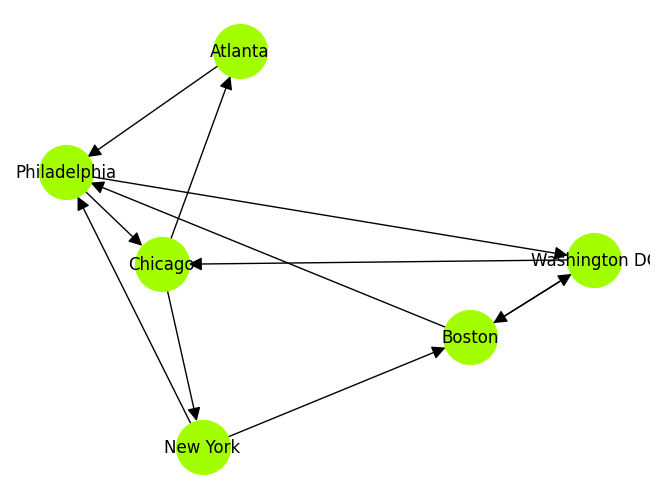

In [66]:
A_distance_dense = A_distance.toarray()
A_duration_dense = A_duration.toarray()

cities = list(G.nodes())

G1 = nx.from_numpy_array(
    A_distance_dense,
    create_using=nx.DiGraph()
)

G1 = nx.relabel_nodes(
    G1,
    dict(enumerate(cities))
)

G2 = nx.from_numpy_array(
    A_duration_dense,
    create_using=nx.DiGraph()
)

G2 = nx.relabel_nodes(
    G2,
    dict(enumerate(cities))
)

nx.draw(
    G1,
    with_labels=True,
    node_color="#A3FF00",
    node_size=1500,
    arrows=True,
    arrowsize=20
)

plt.show()

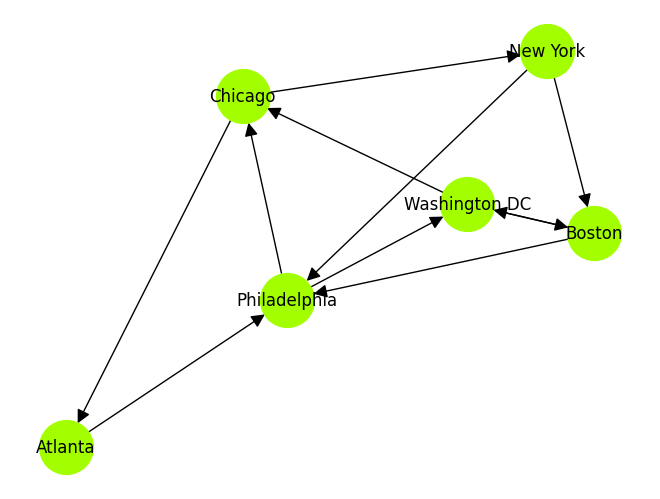

In [67]:
nx.draw(
    G2,
    with_labels=True,
    node_color="#A3FF00",
    node_size=1500,
    arrows=True,
    arrowsize=20
)

plt.show()